# Module 4: [Supervised Learning] Model Interpretability (“opening the black box”)

_Instructor: Dmytro Tymoshenko_

<!--<iframe width="640" height="360" src="YOUTUBE EMBED LINK" title="YouTube video player" frameborder="0" allow="accelerometer; autoplay; clipboard-write; encrypted-media; gyroscope; picture-in-picture; web-share" referrerpolicy="strict-origin-when-cross-origin" allowfullscreen></iframe>
-->

<iframe src="../slides/Module4.pdf" width=100% height="700px" allow="autoplay"></iframe>

## Opening the black box

We are usually calling machine learning models **"black boxes"**, which are giving you a prediction without a reason you can inspect. **Inputs and outputs are visible** resulting in possibility of training and evaluation based on metrics, but the **logic connecting them isn't**, leaving the question of "how you can trust the model?" opened. Or is it so?

**Explainable AI (XAI) framework** employs methods to answer it, so you can trust the model, debug it, audit it, and learn biology from it. As a result, we can get **Improved decision-making**, **Increased trust and acceptance** and **Reduced risks and liabilities**.

### Complexity vs Explainability

**Simple models** such as linear or logistic regression and single decision trees are **intrinsically interpretable**, higher complexity tree-based methods can be relatively reliably interpreted (XGBoost, Random Forest etc), and **deep nets** can usually only be **approximated by specific explanation methods**.

**More complex models allow us to achieve higher precision, but the explainability drops significantly.**

### Model-specific vs model-agnostic approaches

Interpretation methods come in two camps.
**Model-specific** ones read the model's own structure, such as **linear model's coefficients** or **tree's logic splits**. They are cheap, exact and instant, but they only work for that model family, and they flatter whatever the model happens to lean on (impurity importance is biased toward continuous, high-cardinality features).

**Model-agnostic** ones treat the model as a black box and ask only for its predictions, approximating feature importances. They can explain *any* model with, but given the nature of the approach, result depends on that choice.

In [8]:
# PyPi
# %pip install pandas numpy matplotlib scikit-learn tensorflow shap xgboost shapiq shapash lime explainerdashboard ipywidgets
# PyPi with pinned packages
# %pip pandas==2.2.3 numpy==2.1.3 matplotlib==3.10.0 scikit-learn==1.8.0 tensorflow==2.20.0 shap==0.52.0 xgboost==3.4.1 shapiq==1.7.0 shapash==2.9.0 lime==0.2.0.1 explainerdashboard==0.5.3 ipywidgets==8.1.9

In [9]:
# Lets do some basic imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from copy import copy

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

# Model preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Model evaluation
from sklearn.metrics import accuracy_score, f1_score
from sklearn.metrics import roc_auc_score

# Explainability evaluation
from sklearn.metrics.pairwise import cosine_similarity
from scipy.stats import spearmanr

# Explainers
from sklearn.tree import export_text
from sklearn.inspection import permutation_importance
import shap
from shapash import SmartExplainer
import shapiq

### Helper functions

In [ ]:
# Model evaluation

def performance_eval(y_test, y_pred, y_score):

    accuracy=accuracy_score(y_test, y_pred)
    f1=f1_score(y_test, y_pred)

    # Evaluation
    print(f"Accuracy : {accuracy:.2%} | of all test samples, fraction where y_pred == y_test")
    print(f"F1 score : {f1:.2%} | is the harmonic mean of precision (how many of the positive predictions made by the model are actually correct) and recall (how many of the actual positive cases were correctly identified by the model)")

    roc_auc=roc_auc_score(y_test, y_score)

    print(f"roc_auc  : {roc_auc:.2%} | probability that a random class-1 sample gets a higher score than a random class-0 sample")

# directly matplotlib
def plot_features(vals, cols, title="Chart", top_n=10):
    pairs = sorted(zip(cols, abs(vals)), key=lambda pair: pair[1], reverse=True)[:top_n]
    top_cols, top_vals = zip(*pairs)
    plt.barh(top_cols[::-1], top_vals[::-1])   # reversed: barh draws first at bottom
    plt.title(title)
    plt.tight_layout()
    plt.show()

# Function for visualization of the results
# We need: values to plot, labels/columns, title for fun

def plot_features_pd(vals, cols, title="Chart", top_features=10):
    series = pd.Series(abs(vals), index=cols)
    series_top = series.nlargest(top_features)[::-1]

    # xerr = pd.Series(errs, index=cols).loc[top.index]
    
    graph=series_top.plot.barh(title=title)

    # xerr = pd.Series(errs, index=cols).loc[top.index]

    return graph

    # pd.Series(vals, index=cols).nlargest(10).plot.bar(title=title, rot=45) # Label offset issue

## Data: NHANES I Dataset

**NHANES I** (US National Health and Nutrition Examination Survey, 1971–75) joined to mortality follow-up from the **NHANES I Epidemiologic Followup Study (NHEFS, through 1992)**.

Given our models of choice to work with (**RandomForest**, **MLP**) and focus of our work, we are using pre-processed and filtered version of the dataset.

Full version can be pulled as pre-built in shap: `X, y = shap.datasets.nhanesi()`

In [11]:
# Exploring original dataset / how to import pre-built datasets from shap
X, y = shap.datasets.nhanesi()

n_samples_filled=X.dropna().shape[0]

print(f"Samples without N/A: {n_samples_filled} / {X.shape[0]}")
print("Missing values per column:")
print(X.isna().sum().sort_values(ascending=False).head(5))

Samples without N/A: 0 / 14264
Missing values per column:
creatinine         11682
BUN                11338
potassium          11280
sodium             11269
total_bilirubin     8450
dtype: int64


Therefore, we are using pre-processed variant of the dataset.

It contains:
 - **4659** patient samples
 - **19** clinical numerically encoded **features**: `sex_isFemale`	`age`	`physical_activity`	`serum_albumin`	`serum_protein`	`red_blood_cells`	`white_blood_cells`	`hemoglobin`	`hematocrit`	`cholesterol`	`urine_pH`	`sedimentation_rate`	`systolic_blood_pressure`	`pulse_pressure`	`bmi`	`urine_albumin`	`urine_glucose`	`urine_hematest`	`platelets`
 - **1 binary target**: `died_within_10y`

In [ ]:
# Backup - Google Drive
# DATA_URL = "https://drive.google.com/uc?export=download&id=1F8zCozMlFdJ8vtbxgieyqR9gGmTihmrK"
# nhanesi_raw_df = pd.read_csv(DATA_URL)

nhanesi_raw_df=pd.read_csv(f"./data/nhanesi_preprocessed.csv")

X = nhanesi_raw_df.drop(columns=["age", "died_within_10y"])
y = nhanesi_raw_df["died_within_10y"]

# Let's explore it
print(X.shape)
print(y.value_counts(normalize=True).round(2)) # Class distribution

n_samples_filled=X.dropna().shape[0]
print(f"Samples without empty features: {n_samples_filled} | Total: {X.shape[0]}")

(4659, 18)
died_within_10y
0    0.55
1    0.45
Name: proportion, dtype: float64
Samples without empty features: 4659 | Total: 4659


### Data preparation

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler=StandardScaler()

#  Normalization is critical for methods which can develop bias because of absolute values
X_train_scaled=pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_scaled=pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

## Linear & Logistic Regression

In [14]:
LogReg=LogisticRegression(random_state=42)

LogReg.fit(X_train_scaled, y_train)

y_pred=LogReg.predict(X_test_scaled)

y_score = LogReg.predict_proba(X_test_scaled)[:,1] #  (n_samples, n_classes) => roc_auc/pr_auc assume y_score is a positive class

performance_eval(y_test, y_pred, y_score)

Accuracy : 73.50% | of all test samples, fraction where y_pred == y_test
F1 score : 69.01% | is the harmonic mean of precision (how many of the positive predictions made by the model are actually correct) and recall (how many of the actual positive cases were correctly identified by the model)
roc_auc  : 81.95% | probability that a random class-1 sample gets a higher score than a random class-0 sample



### Coefficients (build-in)

Stored in a fitted attribute: `.coef`

- linear combination of input features (y = c<sub>1</sub>x<sub>1</sub> + ... + c<sub>n</sub>x<sub>n</sub> + b)
- Straightforward interpretation:  ↑ value → ↑ importance, ↓ value → ↓ importance

<class 'numpy.ndarray'> (1, 18)
(18,)


<Axes: title={'center': 'Logistic Regression | Coefficients'}>

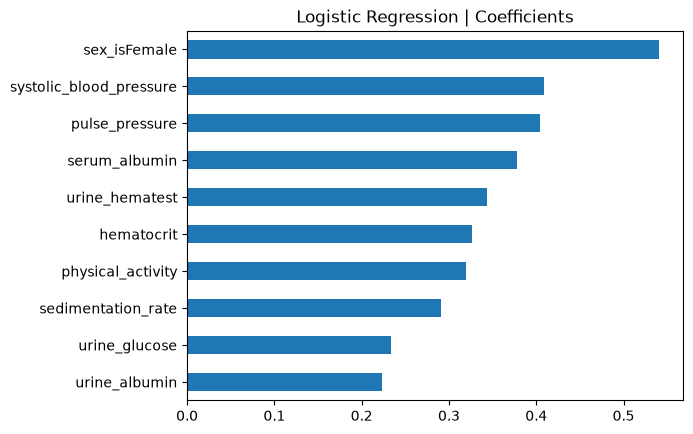

In [15]:
LogReg.coef_
print(type(LogReg.coef_), LogReg.coef_.shape) # N1

""" N1
For regression .coef_: [val1, val2, val3, ...]      ===> (19,)   (usually expected for plotting)
For classification   : [[val1, val2, val3, ...]] ===> (1, 19)  ==> therefore, .coef_[0]
"""
print(LogReg.coef_[0].shape)
plot_features_pd(LogReg.coef_[0], X.columns, "Logistic Regression | Coefficients")

## Decision tree based models

In [16]:
RF_clf=RandomForestClassifier(n_estimators=300, random_state=42)
RF_clf.fit(X_train, y_train)

y_pred=RF_clf.predict(X_test)
y_score=RF_clf.predict_proba(X_test)[:,1]

performance_eval(y_test, y_pred, y_score)

Accuracy : 75.00% | of all test samples, fraction where y_pred == y_test
F1 score : 71.27% | is the harmonic mean of precision (how many of the positive predictions made by the model are actually correct) and recall (how many of the actual positive cases were correctly identified by the model)
roc_auc  : 80.48% | probability that a random class-1 sample gets a higher score than a random class-0 sample


### Feature importances (built-in)

Computed as the mean and standard deviation of accumulation of the impurity decrease within each tree.
Stored as fitted attribute: `.feature_importances_`

  - based on the **training** data
  - high-cardinality/continuous features bias
  - correlated features split the credit

<Axes: title={'center': 'Random Forest | feature_importances_'}>

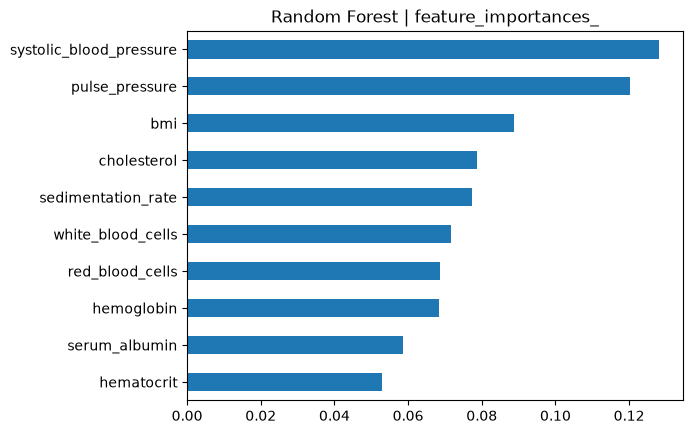

In [17]:
RF_clf.feature_importances_.shape

plot_features_pd(RF_clf.feature_importances_, X.columns, "Random Forest | feature_importances_")

### .estimators_ with export_text/export_graphviz

Allows to peek into individual tree structure(s) via attribute `.estimators_`

```python
from sklearn.tree import export_text
from sklearn.tree import export_graphviz
```

In [18]:
len(RF_clf.estimators_)

rules = export_text(RF_clf.estimators_[1], feature_names=X.columns)
print(rules)

|--- systolic_blood_pressure <= 137.00
|   |--- sex_isFemale <= 0.50
|   |   |--- platelets <= 0.50
|   |   |   |--- serum_protein <= 8.15
|   |   |   |   |--- bmi <= 18.97
|   |   |   |   |   |--- serum_albumin <= 4.15
|   |   |   |   |   |   |--- class: 1.0
|   |   |   |   |   |--- serum_albumin >  4.15
|   |   |   |   |   |   |--- serum_albumin <= 4.25
|   |   |   |   |   |   |   |--- class: 0.0
|   |   |   |   |   |   |--- serum_albumin >  4.25
|   |   |   |   |   |   |   |--- bmi <= 16.93
|   |   |   |   |   |   |   |   |--- class: 1.0
|   |   |   |   |   |   |   |--- bmi >  16.93
|   |   |   |   |   |   |   |   |--- hematocrit <= 43.50
|   |   |   |   |   |   |   |   |   |--- red_blood_cells <= 4.62
|   |   |   |   |   |   |   |   |   |   |--- class: 0.0
|   |   |   |   |   |   |   |   |   |--- red_blood_cells >  4.62
|   |   |   |   |   |   |   |   |   |   |--- class: 1.0
|   |   |   |   |   |   |   |   |--- hematocrit >  43.50
|   |   |   |   |   |   |   |   |   |--- class: 1.0

## ANN: MLP Classifier

For ANNs, there are no built-in attributes to explore it's decision making process, therefore, using external packages is the only option.

In [19]:
# Proper parameter test & optimization: Kfold + GridSearchCV

MLP_clf = MLPClassifier(
    hidden_layer_sizes=(32,16),
    alpha=0.1,
    early_stopping=True,
    max_iter=1000,
    random_state=42,
)

MLP_clf.fit(X_train_scaled, y_train)

y_pred = MLP_clf.predict(X_test_scaled)
y_score = MLP_clf.predict_proba(X_test_scaled)[:,1]

performance_eval(y_test, y_pred, y_score)

Accuracy : 74.03% | of all test samples, fraction where y_pred == y_test
F1 score : 70.20% | is the harmonic mean of precision (how many of the positive predictions made by the model are actually correct) and recall (how many of the actual positive cases were correctly identified by the model)
roc_auc  : 81.84% | probability that a random class-1 sample gets a higher score than a random class-0 sample


## Permutation Importance

Highly versatile & universal technique, works by randomly shaffling data points for one attribute at a time and measuring how it affects the baseline.

_What happens to my score if this feature is scrambled?_

```python
from sklearn.inspection import permutation_importance
```

In [20]:
# Random Forest
RF_clf_perm_res=permutation_importance(RF_clf, X_train, y_train,
                                       n_repeats=10,
                                       random_state=42,
                                       scoring="f1"
                                       )

What is stored inside of the permutation result:
importances_mean
importances_std
importances


<Axes: title={'center': 'Random Forest | Permutation Importance'}>

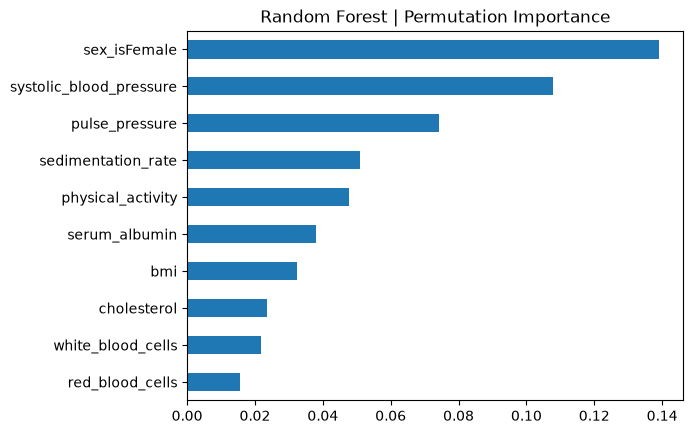

In [21]:
# sklearn.utils._bunch.Bunch object => dict
print("What is stored inside of the permutation result:")
for key, value in RF_clf_perm_res.items():
    print(key)

plot_features_pd(RF_clf_perm_res.importances_mean, X.columns, "Random Forest | Permutation Importance")

<Axes: title={'center': 'MLP | Permutation importance'}>

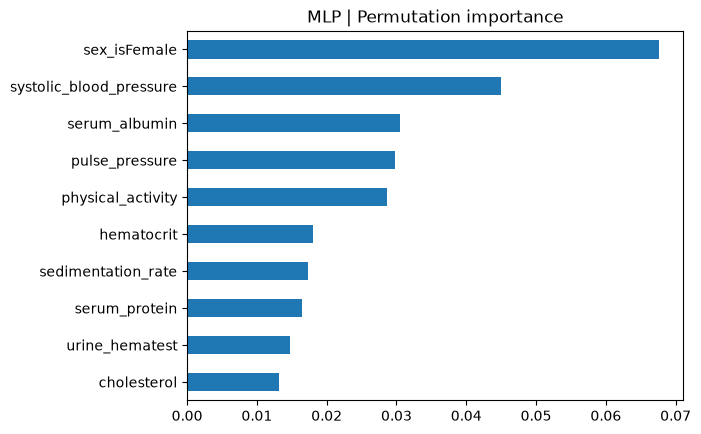

In [22]:
# Multilayer perceptron
MLP_clf_perm_res=permutation_importance(MLP_clf, X_train_scaled, y_train,
                                        n_repeats=10,
                                        random_state=42,
                                        scoring="f1")

plot_features_pd(MLP_clf_perm_res.importances_mean, X.columns, "MLP | Permutation importance")

## **SHAP**: **SH**apley **A**dditive Ex**P**lanations

Explains an individual model prediction by assigning a contribution to each input feature. The main idea is to quantify how much each feature contributes to the difference between a baseline prediction and the prediction for the individual instance.

  - **Model-agnostic** technique
  - Based on shapeley values (cooperative game theory)
  - Flexible for **global** and **local** interpretation
  - **contrastive** method (how **features** move the model from the **baseline**)

  ```python
  import shap
  ```

In [23]:
# For faster calculations
X_test_small=X_test.iloc[:200,:]
X_test_scaled_small=X_test_scaled.iloc[:200,:]

y_test_small = y_test.loc[X_test_small.index]

### SHAP: Tree Explainer

Based on the **tree's own path statistics**, `TreeExplainer` pushes feature subsets down the tree paths in polynomial time (considered good/efficient/managable).

In [24]:
RF_explainer = shap.Explainer(RF_clf) # algorithm="tree"
print(type(RF_explainer))

RF_sv = RF_explainer(X_test_small)
RF_sv_values=RF_sv.values
print(RF_sv_values.shape) # 2 slices for two classes

<class 'shap.explainers._tree.TreeExplainer'>
(200, 18, 2)


<Axes: title={'center': 'SHAP values | Random Forest'}>

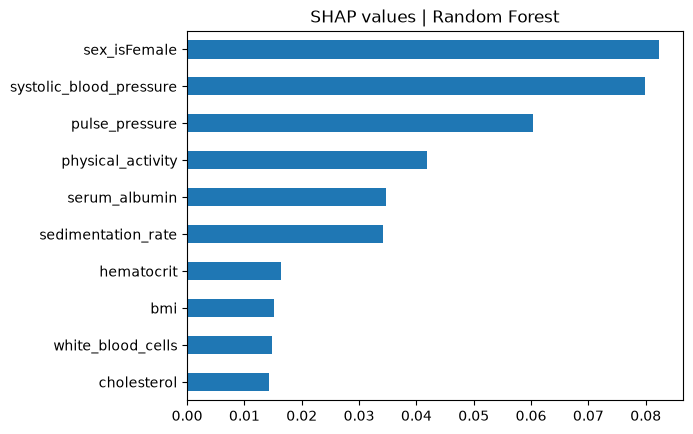

In [25]:
RF_sv_values_mean=np.abs(RF_sv_values[:,:,1]).mean(axis=0)
RF_sv_values_mean.shape

plot_features_pd(RF_sv_values_mean, X.columns, "SHAP values | Random Forest")

### SHAP: Kernel/Permutation Explainers

Given there is nothing to rely on inside the model itself, represent **approximations** that sample coalitions or permutations => slower and noisy.

`KernelExplainer`:
  - old API, cannot be selected in new `Explainer`, but still can be called directly. In new API, `PermutationExplainer` used as a replacement
  - as background, expects **DenseData object with centroids** (k-means clustering)
  -  much slower than the `PermutationExplainer
  - built directly on the `Shapley definition`

Random feature subsets => for other features, substitute from the bg rows => record output => special linear regression on the presence/absense mask => weights are Shapley lernel, coefficients are Shapley values.

_If I only knew some of this person's features, in many different combinations, what is each feature's average added effect on the prediction, once I fit the best consistent weighted explanation across all those combinations?_

<class 'shap.explainers._kernel.KernelExplainer'>


  0%|          | 0/200 [00:00<?, ?it/s]

INFO:shap:num_full_subsets = 2
INFO:shap:remaining_weight_vector = array([0.20732477, 0.16660026, 0.14353254, 0.12957798, 0.12116383,
       0.11662019, 0.11518043])
INFO:shap:num_paired_subset_sizes = 8
INFO:shap:weight_left = np.float64(0.528623703595323)
INFO:shap:np.sum(w_aug) = np.float64(18.0)
INFO:shap:np.sum(self.kernelWeights) = np.float64(0.9999999999999997)
INFO:shap:phi = array([-0.08637677,  0.        ,  0.02768152,  0.        ,  0.03553544,
        0.        ,  0.        , -0.03261929, -0.03855231,  0.        ,
        0.05067463,  0.02519697,  0.02606122,  0.        ,  0.014294  ,
        0.        ,  0.        , -0.02342341])
INFO:shap:np.sum(w_aug) = np.float64(18.0)
INFO:shap:np.sum(self.kernelWeights) = np.float64(0.9999999999999997)
INFO:shap:phi = array([ 0.08637677,  0.        , -0.02768152,  0.        , -0.03553544,
        0.        ,  0.        ,  0.03261929,  0.03855231,  0.        ,
       -0.05067463, -0.02519697, -0.02606122,  0.        , -0.014294  ,
     

<Axes: title={'center': 'SHAP values | MLP Kernel clf'}>

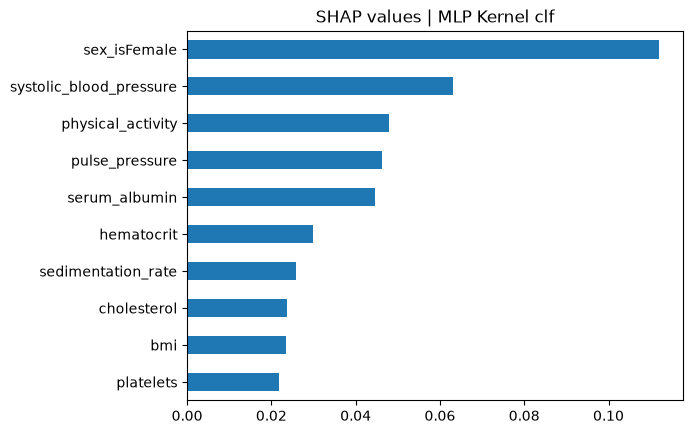

In [26]:
# background = what the model has seen (train)
# explained = what you want to understand (test/new data)

bg=shap.kmeans(X_train_scaled, 10)

MLP_kernel_explainer=shap.KernelExplainer(
    MLP_clf.predict_proba,
    bg
)

print(type(MLP_kernel_explainer))

MLP_sv_values_kernel = MLP_kernel_explainer.shap_values(X_test_scaled_small)[:,:,1]

MLP_sv_values_mean_kernel=np.abs(MLP_sv_values_kernel).mean(axis=0)

plot_features_pd(MLP_sv_values_mean_kernel, X.columns, "SHAP values | MLP Kernel clf")

`PermutationExplainer`:
  - as background expects **subset of samples**
  - despite sharing word **Permutation**, have significant differences in comparison to `permutation_importance` technique 

  |                        | permutation_importance                             | PermutationExplainer                                     |
| ---------------------- | -------------------------------------------------- | -------------------------------------------------------- |
| What gets permuted     | The values of one column, shuffled across all rows | The order in which features are switched, for one person |
| Needs the true labels? | Yes, it measures the drop in score                 | No, it only needs the model's output                     |
| Result                 | One global number per feature                      | Per-person, per-feature signed contribution              |
| Direction              | Importance only                                    | Positive or negative push                                |

_When I move this person away from a typical person one feature at a time, how much does each step shift the prediction?_

In [27]:
bg=shap.sample(X_train_scaled, 100, random_state=42)

MLP_explainer=shap.Explainer(
    MLP_clf.predict_proba,
    bg,
    seed=42
    )
print(type(MLP_explainer))

MLP_sv_scaled=MLP_explainer(X_test_scaled_small) # Contains values, base_values, data, feature_names
print(MLP_sv_scaled.values.shape)      # shap values per feature per class
print(MLP_sv_scaled.base_values.shape) # samples x classes instead of probabilites of classes
print(MLP_sv_scaled.data.shape)

<class 'shap.explainers._permutation.PermutationExplainer'>
(200, 18, 2)
(200, 2)
(200, 18)


<Axes: title={'center': 'SHAP values | MLP PermutationExplainer'}>

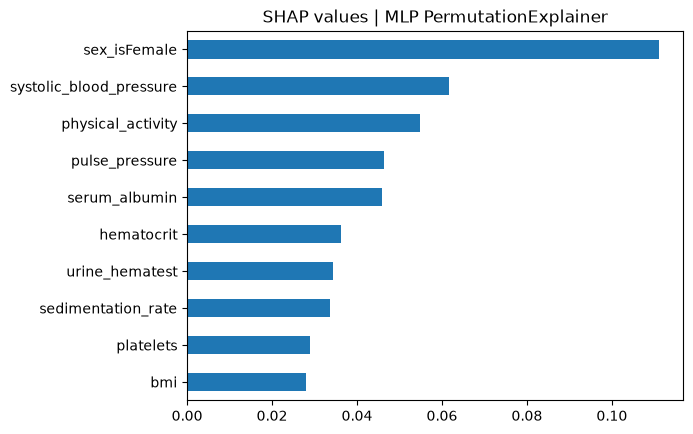

In [28]:
MLP_sv_values=MLP_sv_scaled.values[:,:,1]
MLP_sv_mean=np.abs(MLP_sv_values).mean(axis=0)

plot_features_pd(MLP_sv_mean, X.columns, "SHAP values | MLP PermutationExplainer")

### SHAP: built-in graphs

SHAP package contains multiple advanced packages, which allows you to do interpretation in quick, (relatively) simple and straightforward manner. With new API, you need only **Explanation** object

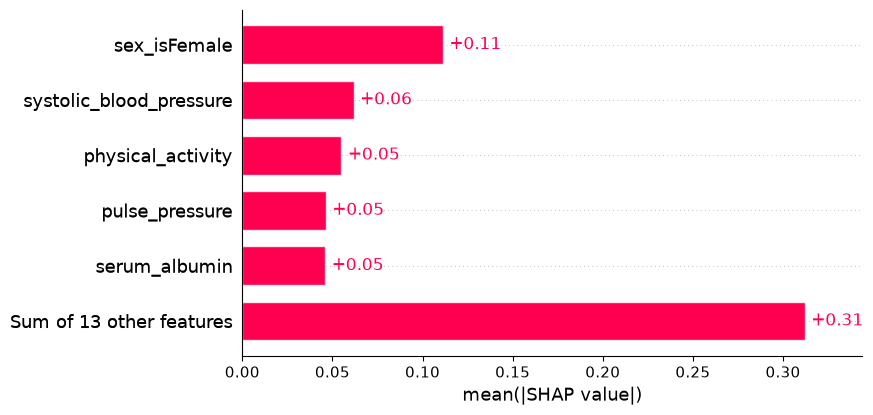

In [29]:
shap.plots.bar(MLP_sv_scaled[:,:,1], max_display=6)

**Bar "mean(|SHAP value|)" plot.** Each bar is the average **|push|** of one feature on the model's risk score across all 932 test patients: "how far from its baseline does a prediction travel just because we know this feature?" (scale = probability, so 0.11 ≈ 11 pp).

- `sex_isFemale` is the strongest single driver (~**0.11**); systolic blood pressure follows (**~0.07**)
- no hero feature: the 13 remaining features **together** add up to ~0.32 => typical for biological datasets

For both class slices in binary classsification, both views are **identical**. Magnitudes don't care about class; **direction does**.


Do survivors and non-survivors get explained the same way?

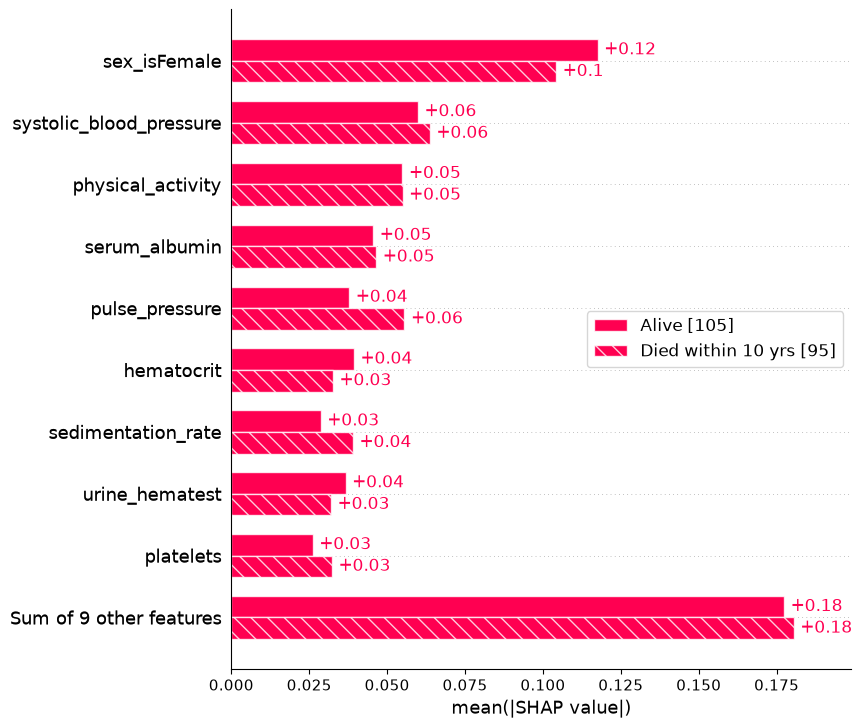

In [30]:
classes=["Alive" if cls==0 else "Died within 10 yrs" for cls in y_test_small]

shap.plots.bar(MLP_sv_scaled[:,:,1].cohorts(classes).abs.mean(0))

**Same magnitudes, split by what actually happened.** Every feature now gets two bars: solid = **Alive** patients [513], striped = **Died within 10 yrs** [419]. Each showing the mean **|push|** inside that group.

- the ranking is nearly identical in both groups: the model leans on the same features whether someone survived or not
- differences are subtle (systolic, pulse and sedimentation_rate slightly louder among the deceased; sex among survivors)

So *how loud* each feature is does not distinguish the groups (in our case, at least). The interesting difference has to be in the **direction**, which |absolute| values throw away. The next plot keeps the signs.

But how much force, and in which direction? Averages hide that.

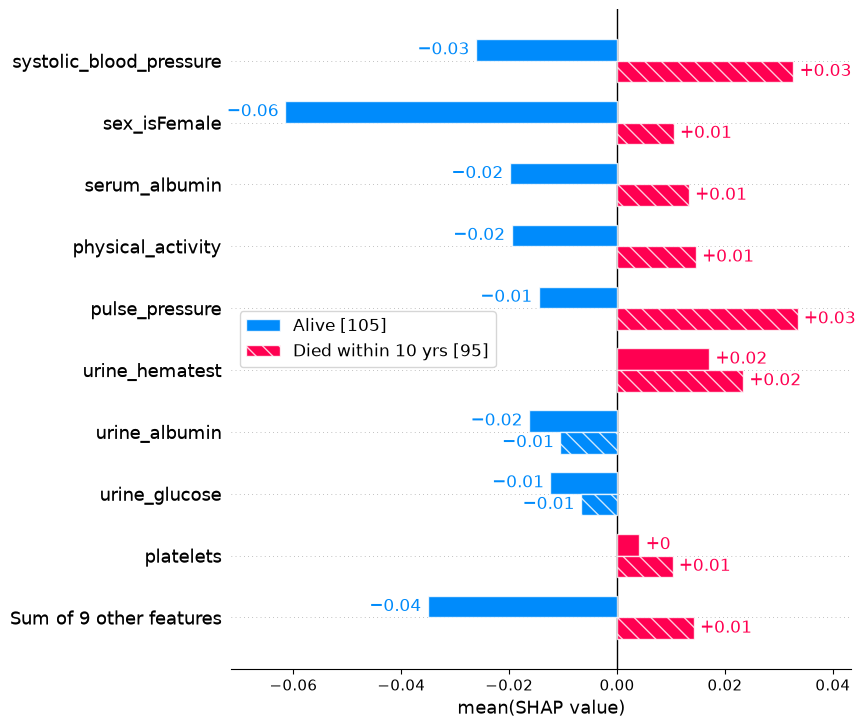

In [31]:
shap.plots.bar(MLP_sv_scaled[:,:,1].cohorts(classes).mean(0))

**Absolute cohorts plot**

Every bar still measures "push on the **Died** score" ([:,:,1] slice), but now it pushes averages *within* groups of patients who in reality lived or died.

- **Alive cohort** [513]: nearly all bars point **left/negative**: `sex_isFemale` −0.06, systolic −0.02, physical_activity −0.02. For a survivor, these features on average pushed **away** from the death class.
- **Died cohort** [419]: the same features flip to **positive**: systolic +0.04, pulse_pressure +0.04.

For a per-patient view we plot each person's SHAP value against their own feature value — starting with one feature.


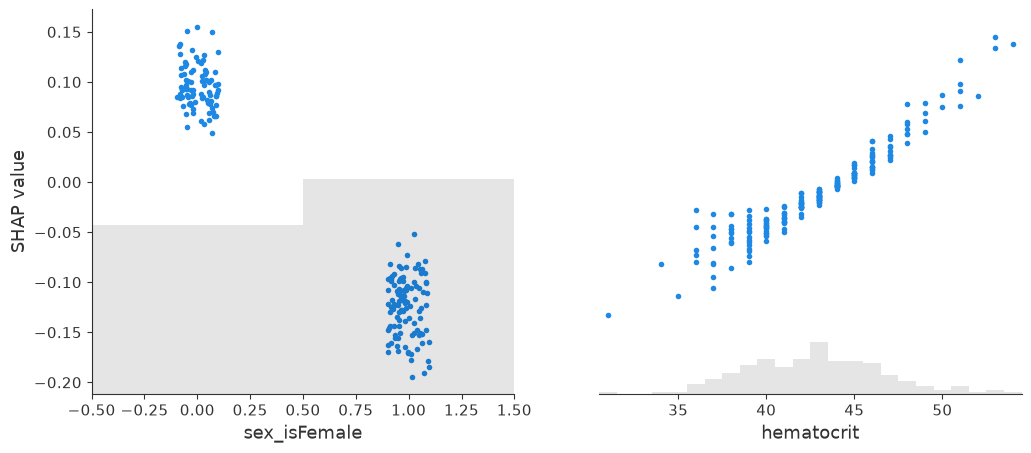

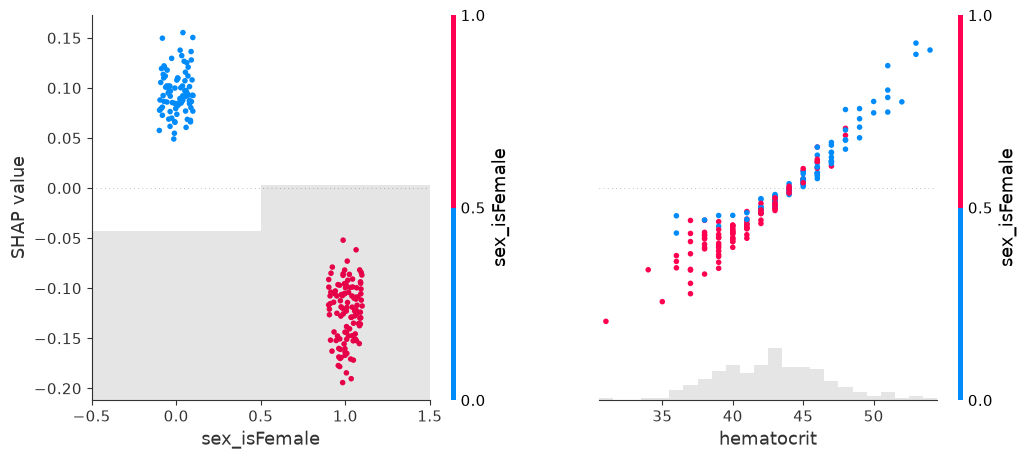

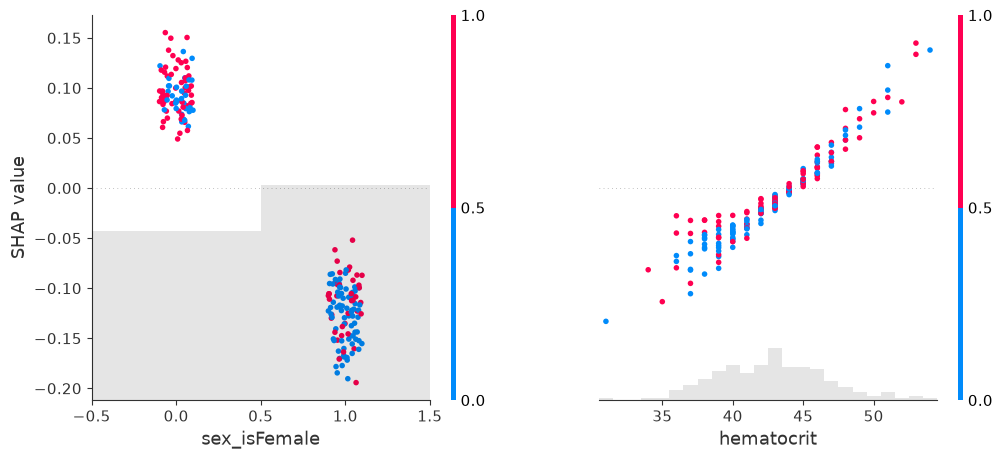

In [32]:
# As far as we now can observe actual values, and our data passed via StandardScaler,
# we can "switch" it to the actual data

MLP_sv=copy(MLP_sv_scaled)
MLP_sv.data=scaler.inverse_transform(MLP_sv_scaled.data)

shap.plots.scatter(MLP_sv[:, ["sex_isFemale", "hematocrit"], 1])

# Multiple features with feature color coding
shap.plots.scatter(MLP_sv[:, ["sex_isFemale", "hematocrit"], 1], color=MLP_sv[:, "sex_isFemale", 1])

# Multiple features with target color coding
shap.plots.scatter(MLP_sv[:, ["sex_isFemale", "hematocrit"], 1], color=y_test_small.values)

**Scatter plot.** One dot = one patient; x = that patient's `sex_isFemale` value; y = the push that value gave their risk score.

`sex_isFemale` is binary, so the dots fall into two strips: ≈ **−1.06** (male) and ≈ **+0.94** (female). The model works on **StandardScaler-adjusted** inputs, so axes are in scaled units (how far from the cohort average, in standard deviations). The grey histogram at the bottom shows where patients actually sit.

- the male strip sits entirely **above zero** (+0.05 … +0.15): being male pushed each of these patients **toward** "Died within 10 yrs"
- the female strip sits entirely **below zero** (−0.20 … −0.05): being female pushed risk **down**
- complete separation like this is a strong, one-directional signal, and it matches the known sex difference in 10-year mortality for this cohort

The **beeswarm** below is the "every feature, every patient" edition of this plot.


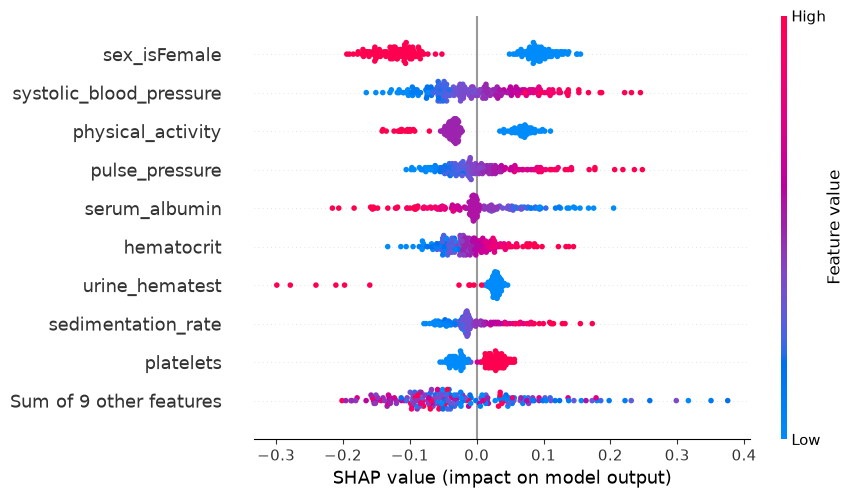

In [33]:
# Selective picking of the features
# shap.plots.beeswarm(MLP_sv[:,["sex_isFemale", "systolic_blood_pressure"],1])

shap.plots.beeswarm(MLP_sv[:,:,1])

**Beeswarm plot.** One dot = one patient × one feature, rows sorted by importance (top = loudest). x = push on the risk score (right = toward "Died", left = away); **colour = the feature's own value** (red = high, blue = low).

- `systolic_blood_pressure`: red (high BP) stretches furthest to the right => the strongest one-directional risk **↑** push in the model; `pulse_pressure` mirrors it
- `serum_albumin` and `physical_activity`: red (high values) on the **left** => better nutrition and activity pull risk down

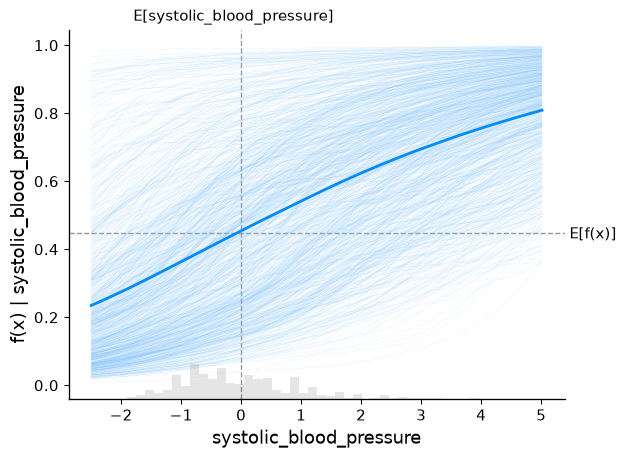

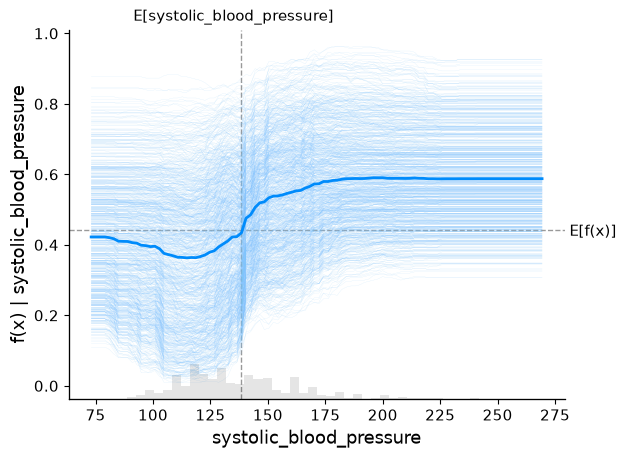

In [34]:
shap.plots.partial_dependence(
    "systolic_blood_pressure",
    lambda data: MLP_clf.predict_proba(data) [:,1],
    X_test_scaled,
    ice=True,
    model_expected_value=True,
    feature_expected_value=True
)

shap.plots.partial_dependence(
    "systolic_blood_pressure",
    lambda data: RF_clf.predict_proba(data) [:,1],
    X_test,
    ice=True,
    model_expected_value=True,
    feature_expected_value=True
)

**Partial dependence + ICE.** x = serum_albumin (scaled units, 0 = cohort average); y = predicted 10-year mortality risk.

- thick blue line (**PDP**) = average model output when every patient is set to that pressure: rises in the same direction the beeswarm suggested
- thin lines (**ICE**) = individual patients: most climb in parallel, each starting from their own level. The wide spread says pressure never acts alone, but its direction is consistent for almost everyone
- dashed guides: horizontal at **E[f(x)] ≈ 0.477** => the average prediction (our SHAP baseline); vertical at **E[feature]** => the average patient's value/mean of the feature.

In [35]:
# For clustering => pairwise XGBoost, distance 0(reduntant)-1(independent)

MLP_clustering=shap.utils.hclust(X_test, y_test)

c:\Users\timos\miniforge3\envs\mle_2610_m4\Lib\site-packages\shap\utils\_clustering.py:195: UserWarning:

No/low signal found from feature 17 (this is typically caused by constant or near-constant features)! Cluster distances can't be computed for it (so setting all redundancy distances to 1).



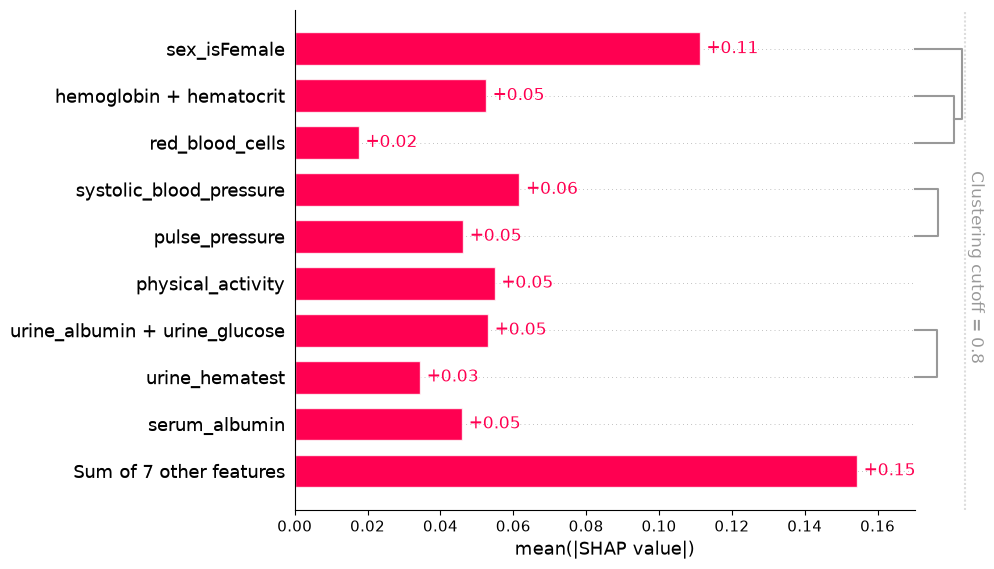

In [36]:
shap.plots.bar(MLP_sv[:,:,1], clustering=MLP_clustering, clustering_cutoff=0.8, max_display=10)

**Ranking, now correlation-aware.** The dendrogram groups features that behave *alike* across patients (hierarchical clustering of their SHAP patterns; dashed line = cutoff 0.9). What it does to the display:

- `hemoglobin + hematocrit` collapse into a **single bar** (~0.05 combined) => one physiological axis (oxygen transport).
- `systolic + pulse_pressure` (blood-pressure pair) and `urine_hematest + urine_glucose + urine_albumin` (protein/inflammation axis) form tight groups too.

Features inside one tight cluster **share credit**: they are partial substitutes for each other, so ranking them head-to-head (or summing them) overstates their independent effect.

## SHAP: Local explanations

Everything so far summarized the whole test set: which features matter **on average** (bars), in **which direction** (beeswarm), and how the picture **splits by outcome** (cohorts).

But sometimes we need to look beyond "the average sample". SHAP's additional feature is one level down: explaining *why the model said what it said for _this particular sample_. We can zoom in step by step: heatmap (all patients, ordered) → decision plot (a handful of paths) → waterfall & force (one patient).

We start with the **heatmap**: many patients at once, while every individual push stays visible.


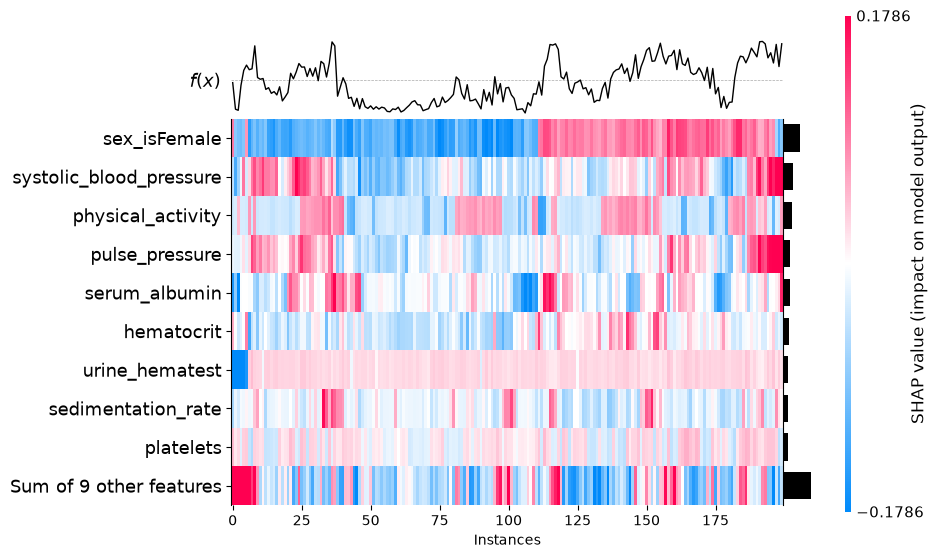

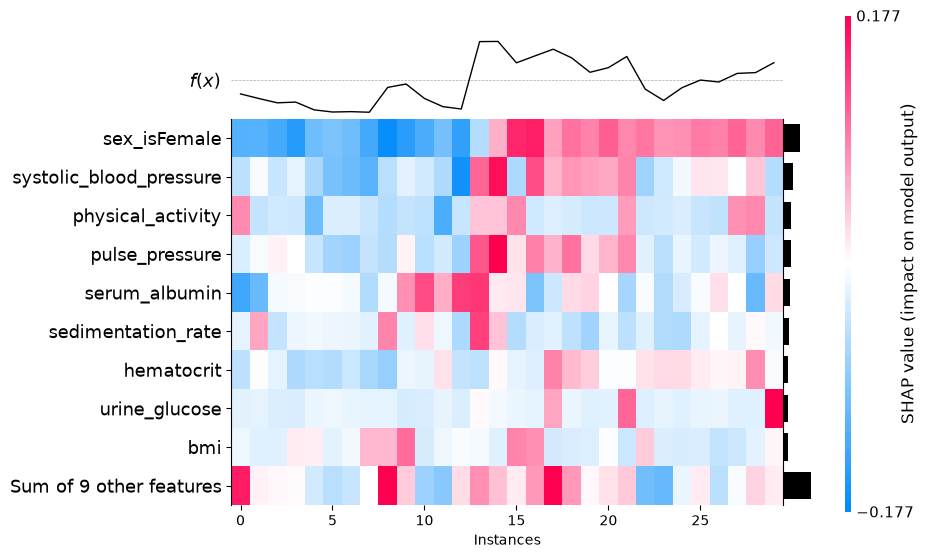

<Axes: xlabel='Instances'>

In [37]:
shap.plots.heatmap(MLP_sv[:,:,1])

shap.plots.heatmap(MLP_sv[:30,:,1]) # We can subset any number of samples (2+), order != order in data

**Heatmap.** Columns = the 932 test patients, **ordered so that similar explanations sit together** (supervised clustering on the SHAP vectors). Top black curve = each patient's model output; dashed grey line = the baseline E[f].

- each cell = one patient's push for that row feature.
- the `sex_isFemale` row swings blue → red left-to-right: female-heavy (blue, risk-down) patients cluster on the left, male-heavy on the right.

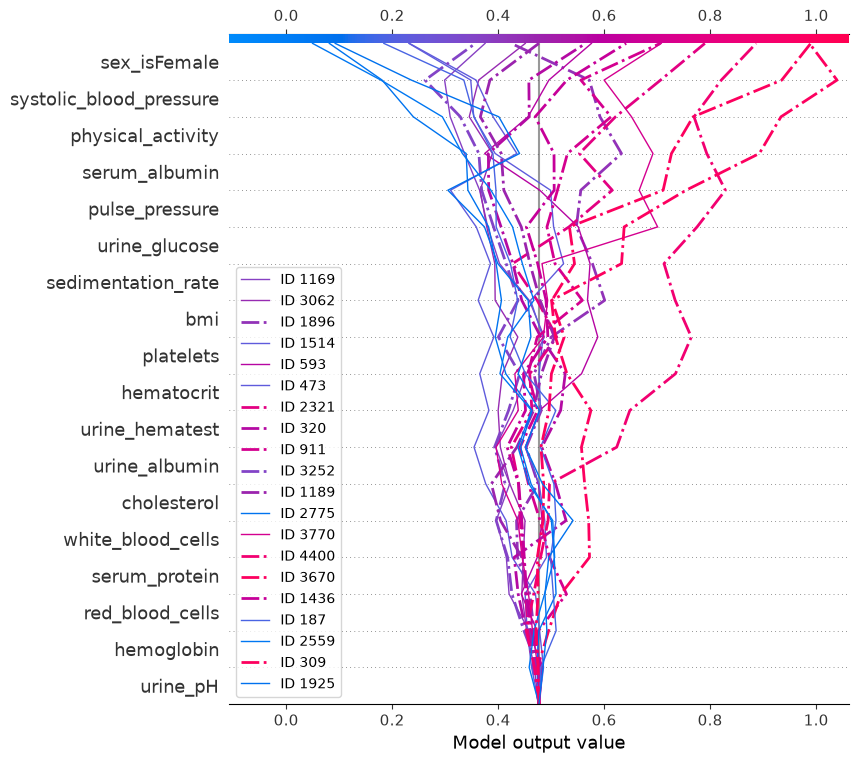

In [38]:
# A readable subset: 10 Alive + 10 Died patients (dashed = actually died)

# Subsetting samples - 10 each class
num_samples=10

classes=np.where(np.asarray(y_test) == 0, "Alive", "Died within 10 yrs")
alive_idx = np.where(classes == "Alive")[0][:num_samples]
died_idx = np.where(classes == "Died within 10 yrs")[0][:num_samples]
sub=np.sort(np.concatenate([alive_idx, died_idx]))

# Function was not adapted for new Explanation object, so we need:
base_value    = MLP_sv.base_values[0,1]
shap_values   = MLP_sv.values[sub,:,1]
feature_names = MLP_sv.feature_names
highlight     = np.isin(sub, died_idx) # No built-in option to provide a legend here
legend_labels = [f"ID {idx}" for idx in X_test.index[sub]]

# And now we can plot:
shap.plots.decision(
    base_value,
    shap_values,
    feature_names=feature_names,
    highlight=highlight,
    legend_labels=legend_labels
)

**Decision plot: the bridge from global to local.** Each line is one patient's explanation drawn as a path: it starts at the baseline (bottom, E[f] ≈ 0.477) and every step upward adds one feature's push for that person (features ordered by importance), ending at their predicted risk.

- lines ending **left** of the base = net pushed down; ending **right** = pushed up (pink/red, high risk); line colour = the patient's final risk.

In [39]:
# X_test_scaled_sample = X_test_scaled.loc[[1169], :] # By index
X_test_scaled_sample = X_test_scaled.iloc[[0], :]   # By position
X_test_scaled_sample

,sex_isFemale,physical_activity,serum_albumin,serum_protein,red_blood_cells,white_blood_cells,hemoglobin,hematocrit,cholesterol,urine_pH,sedimentation_rate,systolic_blood_pressure,pulse_pressure,bmi,urine_albumin,urine_glucose,urine_hematest,platelets
1169,-1.062308,0.326456,0.268655,-0.025479,1.399145,-0.849802,1.418794,0.726578,0.896699,-0.772734,-1.033327,-0.320288,-0.405701,1.065809,-0.301763,-0.3061,-0.293405,0.81247


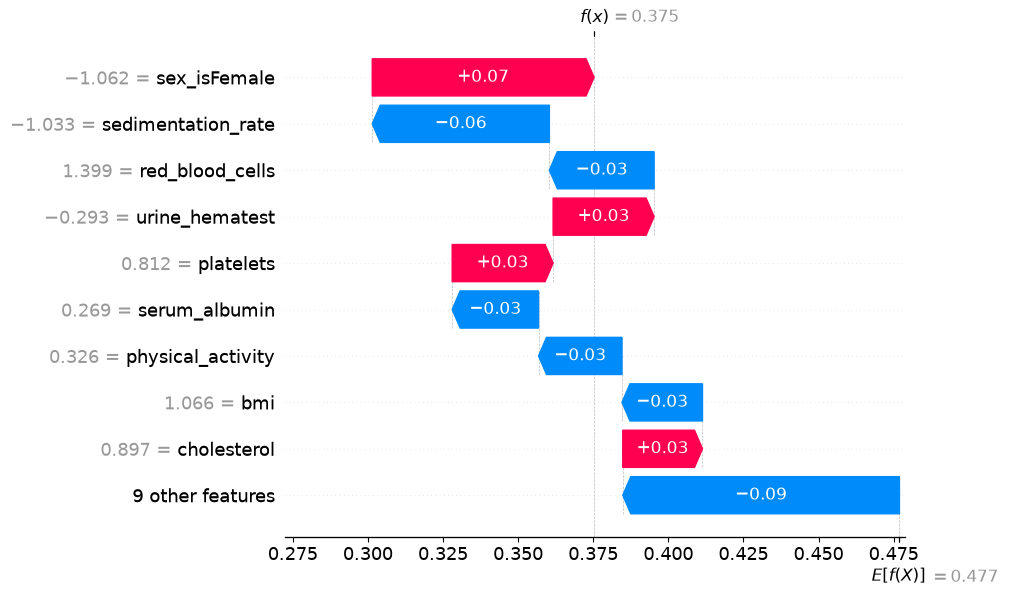

In [40]:
sv_test_sample=MLP_explainer(X_test_scaled_sample, max_evals=2000)

shap.plots.waterfall(sv_test_sample[0,:,1])

**Waterfall plot.** One sample exploration, from the *typical* patient to *this* patient:

- bottom line = **E[f(X)] = 0.477**: the model's average prediction, our baseline
- final score **f(x) = 0.375** → below 0.5, so the model predicts he survives — and he did, one the model got right

Everything is still in the class-1 frame (push on the **dying** score).

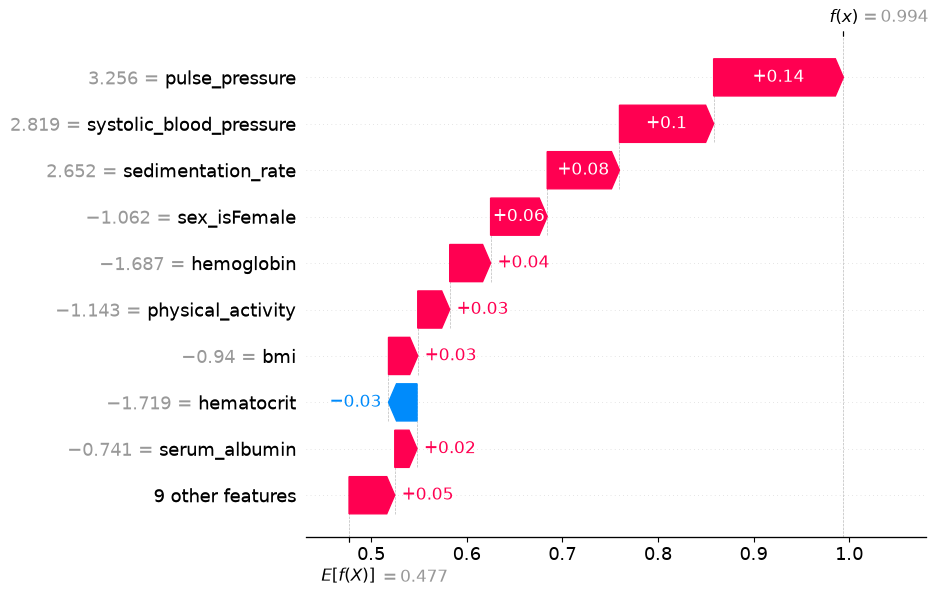

In [41]:
# The mirror case: the test-set patient with the highest predicted risk
idx_risk=np.argmax(MLP_clf.predict_proba(X_test_scaled)[:,1])

X_test_scaled_risk=X_test_scaled.iloc[[idx_risk],:]

sv_risk_sample=MLP_explainer(X_test_scaled_risk, max_evals=2000)

shap.plots.waterfall(sv_risk_sample[0,:,1])


**The mirror case.** Same reading, opposite end of the risk distribution.

Put the two waterfalls side by side and the classification frame shows up again: the **same** features, but local explanations differ in **how much and which way** each feature moves *this* patient.

In [42]:
shap.initjs() # For building force plots, we need js dependency or matplotlib=True
shap.plots.force(sv_test_sample[0, :, 1]) # matplotlib=True

# Swap to actual values for visibility
sv_test_sample.data = X_test.loc[X_test_scaled_sample.index, X_test_scaled_sample.columns].to_numpy()
shap.plots.force(sv_test_sample[0, :, 1])

**Force plot.** Same patient, same SHAP values, one horizontal band: red pushes right (toward "Died"), blue pushes left (away), starting from the base value and ending at f(x).

## SHAP: explanation consistency

Two questions every explanation should survive: retrain the same model with a different seed: does the story hold? And do two different model families agree on what matters? If not, the top-feature story you are telling is fragile.

A quick check for both: turn each model's explanations into its **mean-|SHAP| vector** (the same recipe as the bars above) and compare two such vectors with two numbers:

- **cosine similarity** => do both models split the credit in the same *proportions*? (1 = identical). It is dominated by the largest features, so it tends to be high.
- **Spearman correlation** => do both models *rank* the features the same way? (1 = identical order). Stricter: it also notices disagreement among the small features.

In [43]:
# Different seed for the tree
RF_clf_B=RandomForestClassifier(n_estimators=300, random_state=7)
RF_clf_B.fit(X_train, y_train)

RF_B_explainer = shap.Explainer(RF_clf_B)
RF_B_sv = RF_B_explainer(X_test_small)
RF_B_sv_values=RF_B_sv.values
RF_B_sv_values_mean=np.abs(RF_B_sv_values[:,:,1]).mean(axis=0)

In [44]:
def explanation_consistency(vals1, vals2):
    cosine=cosine_similarity([vals1], [vals2])[0,0]
    spearman=spearmanr(vals1, vals2)[0]

    print(f"Cosine   : {cosine:.3f} | same proportions of credit between features (1 = identical)")
    print(f"Spearman : {spearman:.3f} | same ranking of features (1 = identical order)")

print("RF seed 42 vs RF seed 7")
explanation_consistency(RF_sv_values_mean, RF_B_sv_values_mean)

print("RF vs MLP:")
explanation_consistency(RF_sv_values_mean, MLP_sv_mean)

RF seed 42 vs RF seed 7
Cosine   : 1.000 | same proportions of credit between features (1 = identical)
Spearman : 0.996 | same ranking of features (1 = identical order)
RF vs MLP:
Cosine   : 0.925 | same proportions of credit between features (1 = identical)
Spearman : 0.705 | same ranking of features (1 = identical order)


- **Same model, different seed**: the cosine is 1.000 => for a 300-tree forest, averaging washes out the seed, so the explanations are reproducible.
- **Forest vs ANN**: the cosine is 0.925, high but expected - both models agree on the biggest features, and those dominate the score. The **Spearman** line is the stricter test: the lower it is below the cosine, the more the models disagree on the *order* of the remaining features. Two different models can legitimately use different, correlated features for the same signal.

A habit worth keeping: high agreement between two models means either one tells the same story; clearly lower sends you to the disagreement *before* you trust the ranking.

## SHAP: dashboards (shapash & shapiq)

Everything so far was built plot by plot - great for understanding, tedious for everyday work. Two libraries package the same ideas (both are in the course environment):

- **shapash** - turns a fitted model into ready-made plots plus a browsable web **dashboard** (global importance, per-patient contributions, filters);
- **shapiq** - extends SHAP beyond single features to **interaction values**: how much two features matter *together*, not one at a time.

### shapash: contributions and a browsable dashboard

In [45]:
RF_xpl = SmartExplainer(model=RF_clf, label_dict={0: "Alive", 1: "Died within 10y"})
# y_target is optional, but the dashboard's clustering tab fails without it
RF_xpl.compile(x=X_test_small, y_target=y_test_small)

INFO: Shap explainer type - <shap.explainers._tree.TreeExplainer object at 0x000001810C52A9C0>


In [46]:
RF_xpl.plot.features_importance()

In [47]:
RF_xpl.plot.contribution_plot("systolic_blood_pressure")

**Contribution plot.** Each dot is a patient: x = the feature value, y = how much it pushed that patient's predicted risk (up or down). Read the **shape** of the curve - which values push risk down, which push it up, where it crosses zero - and the **vertical spread** around it: two patients with the same systolic pressure can still get different contributions, because other features interact with it. The strip along the bottom shows how many patients actually sit at each value.

**Can you trust these explanations?** Shapash adds two checks that echo the consistency section above:

- **Stability** - for each feature, average importance (*amplitude*) vs how much its contribution varies among *similar* patients (*variability*). Features that are large **and** stable are the safe part of your story; large but unstable ones deserve caution.
- **Compacity** - how few features reproduce (most of) the model's output?

In [48]:
RF_xpl.plot.stability_plot()

In [49]:
RF_xpl.plot.compacity_plot()

**The dashboard.** `run_app()` serves the compiled explanations as a web app (global importance, contributions, per-patient view, filters). The call is non-blocking: it returns a thread handle and `.kill()` shuts the app down.

In [50]:
app = RF_xpl.run_app(host="127.0.0.1", port=8050)

INFO:root:Your Shapash application run on http://127.0.0.1:8050/
INFO:root:Use the method .kill() to down your app.


In [51]:
app.kill()  # stop the dashboard

### shapiq: interaction values

Single-feature SHAP splits credit one feature at a time; **shapiq** computes *interaction values* - additional credit for features that only matter in combination (pairs here).

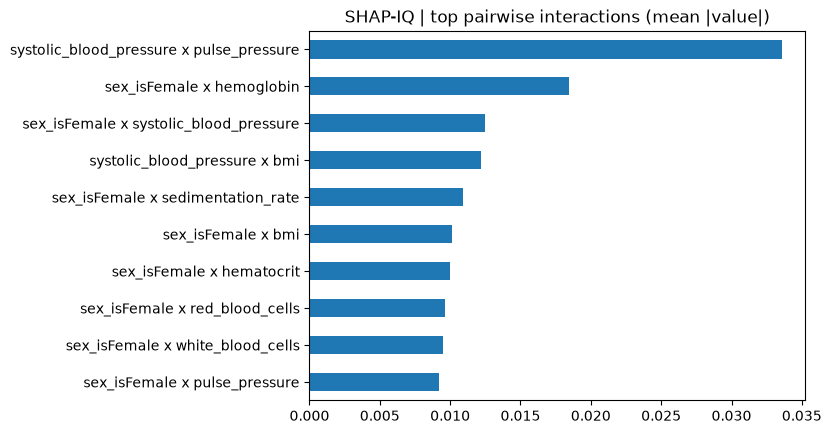

In [52]:
# The same forest & the same 200 patients, now explained with interaction values:
# every attribution is split into single features + pairwise "works together" terms
RF_sq_explainer = shapiq.Explainer(model=RF_clf, index="k-SII", max_order=2, class_index=1)
RF_sq_values = RF_sq_explainer.explain_X(X_test_small.to_numpy())   # one InteractionValues per patient

# Mean |interaction| per feature pair, ranked like the bar plots above
RF_pair_sum = {}
for iv in RF_sq_values:
    for k, v in iv.dict_values.items():      # k = tuple of feature indices
        if len(k) == 2:
            RF_pair_sum[k] = RF_pair_sum.get(k, 0.0) + abs(v)

RF_pair_imp = pd.Series({f"{X.columns[a]} x {X.columns[b]}": s / len(RF_sq_values)
                      for (a, b), s in RF_pair_sum.items()})
ax = plot_features_pd(RF_pair_imp.values, RF_pair_imp.index, "SHAP-IQ | top pairwise interactions (mean |value|)")

Each bar = how much the two features move the prediction **together**, credit the single-feature bars cannot show. Compare the top pair with the top features in the earlier bar plots: strong main effects do not have to interact strongly.